# Health Study – Part 1: Descriptive Analysis and Statistics

## Introduction
In this notebook I analyse data from a health study with 800 participants.
The dataset contains age, sex, height, weight, systolic blood pressure,
cholesterol, smoking habits and whether the person has a certain disease.

The goals of Part 1 are to:
1. Describe the data with basic statistics and graphs.
2. Simulate the disease rate with numpy and compare it with the real data.
3. Calculate a confidence interval for the mean systolic blood pressure.
4. Test if smokers have higher blood pressure than non-smokers.

## 1. Setup
I import the libraries, set a random seed so that all simulations give
the same result every time, and load the data with a relative path.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ตั้ง seed = 42 ตามที่โจทย์กำหนด เพื่อให้สุ่มได้ผลเหมือนเดิมทุกครั้ง
np.random.seed(42)

# อ่านข้อมูลด้วย relative path
df = pd.read_csv("data/health_study_dataset.csv")

df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## 2. Data quality check
Before the analysis I check the size of the data, the data types,
missing values and duplicates. Bad data gives bad results,
so this step is important.

In [2]:
# ขนาดข้อมูล (แถว, คอลัมน์)
print("Shape:", df.shape)

# ดูชนิดข้อมูลของแต่ละคอลัมน์
df.info()

# นับค่าที่หายไปในแต่ละคอลัมน์
print("\nMissing values per column:")
print(df.isnull().sum())

# นับแถวที่ซ้ำกัน (ไม่นับ id เพราะ id ไม่ซ้ำกันอยู่แล้ว)
print("\nDuplicate rows:", df.drop(columns="id").duplicated().sum())

Shape: (800, 9)
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB

Missing values per column:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Duplicate rows: 0


### Check for unusual values
Weight alone does not show if a value is strange, because it depends
on height. Therefore I calculate BMI and look at the lowest values.

In [3]:
# ดูช่วงของค่าตัวเลขทั้งหมด
df.drop(columns="id").describe().round(2)

,age,height,weight,systolic_bp,cholesterol,disease
count,800.00,800.00,800.00,800.00,800.00,800.00
mean,49.43,171.85,73.41,149.18,4.93,0.06
std,14.50,9.80,13.69,12.79,0.85,0.24
min,18.00,144.40,33.70,106.80,2.50,0.00
25%,39.00,164.78,64.80,140.90,4.33,0.00
50%,50.00,171.35,73.20,149.40,4.97,0.00
75%,59.00,178.92,82.60,157.60,5.48,0.00
max,90.00,200.40,114.40,185.90,7.88,1.00


In [4]:
# คำนวณ BMI = น้ำหนัก(kg) / ส่วนสูง(m)^2 เพื่อดูว่าน้ำหนักสมเหตุสมผลกับส่วนสูงไหม
bmi = df["weight"] / (df["height"] / 100) ** 2

# ดู 5 คนที่ BMI ต่ำที่สุด ใส่ค่า BMI ไว้ในตารางเดียวกันให้อ่านง่าย
low_bmi = df.loc[bmi.nsmallest(5).index, ["age", "sex", "height", "weight"]]
low_bmi["bmi"] = bmi.round(1)
print(low_bmi)

# นับคนที่ BMI ต่ำกว่า 16 (ผอมมากตามเกณฑ์ WHO)
print("\nPeople with BMI < 16:", (bmi < 16).sum())

     age sex  height  weight   bmi
535   50   F   163.8    33.9  12.6
249   56   M   184.5    44.1  13.0
756   57   M   185.0    44.8  13.1
23    28   F   170.2    38.1  13.2
783   59   M   189.3    48.8  13.6

People with BMI < 16: 23


### Findings
- The data has 800 rows and 9 columns. There are no missing values
  and no duplicates, and all columns have the correct data types.
- I calculated BMI to check if weight and height make sense together.
  The lowest BMI is 12.6 (woman, 50 years, 163.8 cm, 33.9 kg).
  23 people have a BMI under 16, which WHO classifies as severe thinness.
- These values are unusual but possible, and I cannot prove that they
  are errors. Therefore I keep all rows in the analysis.

## 3. Descriptive statistics
I calculate the mean, median, min and max for the five numeric columns.
The mean shows the average value, and the median shows the middle value.
If they are close, the data is not very skewed.

In [5]:
# คอลัมน์ที่โจทย์ให้คำนวณ
num_cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# คำนวณ 4 ค่าพร้อมกันด้วย agg แล้วกลับตาราง (.T) ให้แต่ละคอลัมน์เป็นแถว อ่านง่ายกว่า
summary = df[num_cols].agg(["mean", "median", "min", "max"]).T
summary.round(2)

,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


**Comment:** The mean and median are almost the same for all columns.
The average participant is about 49 years old. The mean systolic blood
pressure is 149 mmHg, which is above the common limit for high blood
pressure (140 mmHg). In section 4.1 I check how many participants
are above this limit.

## 4. Visualisation
### 4.1 Distribution of systolic blood pressure
A histogram shows how the values are spread. I add a line for the mean
and a line for 140 mmHg (limit for high blood pressure).

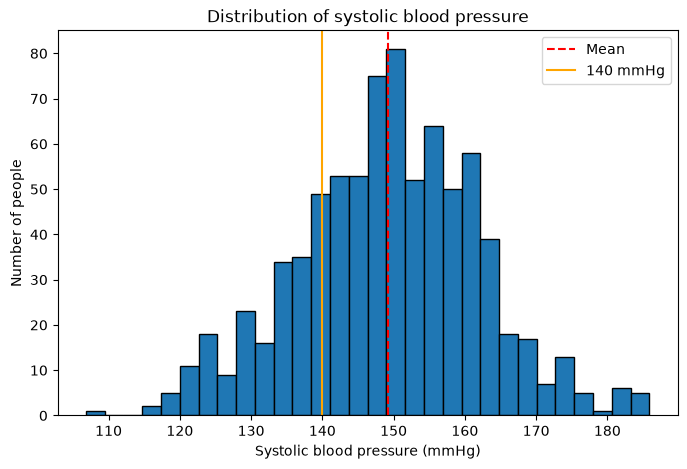

Share above 140 mmHg: 76.9%


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

# วาด histogram แบ่งเป็น 30 ช่อง ใส่ขอบดำให้เห็นแต่ละแท่งชัด
ax.hist(df["systolic_bp"], bins=30, edgecolor="black")

# เส้นประสีแดง = ค่าเฉลี่ย
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Mean")
# เส้นสีส้ม = เกณฑ์ความดันสูง
ax.axvline(140, color="orange", label="140 mmHg")

ax.set_title("Distribution of systolic blood pressure")
ax.set_xlabel("Systolic blood pressure (mmHg)")
ax.set_ylabel("Number of people")
ax.legend()
plt.show()

# คำนวณว่ากี่เปอร์เซ็นต์ที่ความดันเกิน 140
above_140 = (df["systolic_bp"] > 140).mean() * 100
print(f"Share above 140 mmHg: {above_140:.1f}%")

**Comment:** The distribution looks like a bell curve (close to normal).
76.9% of the participants have a systolic blood pressure above 140 mmHg.

### 4.2 Weight by sex
A boxplot shows the median, the spread and possible outliers.
It is a good way to compare two groups.

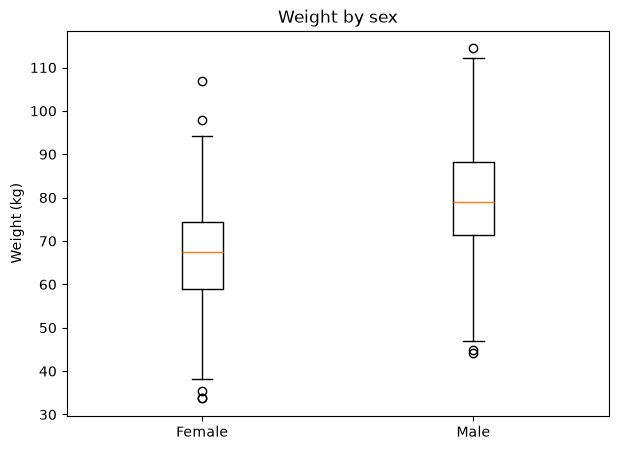

In [7]:
# แยกน้ำหนักเป็น 2 กลุ่มตามเพศ
weight_f = df[df["sex"] == "F"]["weight"]
weight_m = df[df["sex"] == "M"]["weight"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([weight_f, weight_m], tick_labels=["Female", "Male"])

ax.set_title("Weight by sex")
ax.set_ylabel("Weight (kg)")
plt.show()

**Comment:** Men are heavier than women. The median weight is about
79 kg for men and 67 kg for women. Both groups have some outliers,
both low and high. The three lowest points in the female group (33.7–35.5 kg) all have
a BMI under 16, so they are part of the 23 people I found in the
data quality check.

### 4.3 Share of smokers
I use a bar chart with percentages, because percentages are easier
to understand than counts.

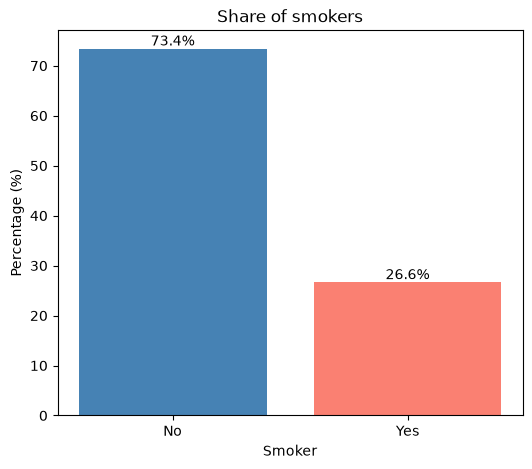

In [8]:
# normalize=True ให้ได้สัดส่วน (0-1) แล้วคูณ 100 เป็นเปอร์เซ็นต์
smoker_share = df["smoker"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(smoker_share.index, smoker_share.values, color=["steelblue", "salmon"])

# เขียนตัวเลข % ไว้บนแต่ละแท่ง
ax.bar_label(bars, fmt="%.1f%%")

ax.set_title("Share of smokers")
ax.set_xlabel("Smoker")
ax.set_ylabel("Percentage (%)")
plt.show()

**Comment:** About 27% of the participants smoke and 73% do not smoke.
The smoker group is smaller, which is important to remember in the
hypothesis test later.